# Pipeline Flow B: Detection, Classification & Counting (Target Set)
Questo notebook gestisce l'esecuzione sequenziale dei singoli moduli del Flow B per la detection, classificazione e conteggio del valore monetario sulle immagini target.


Caricate con successo 142 immagini target da: target_set/


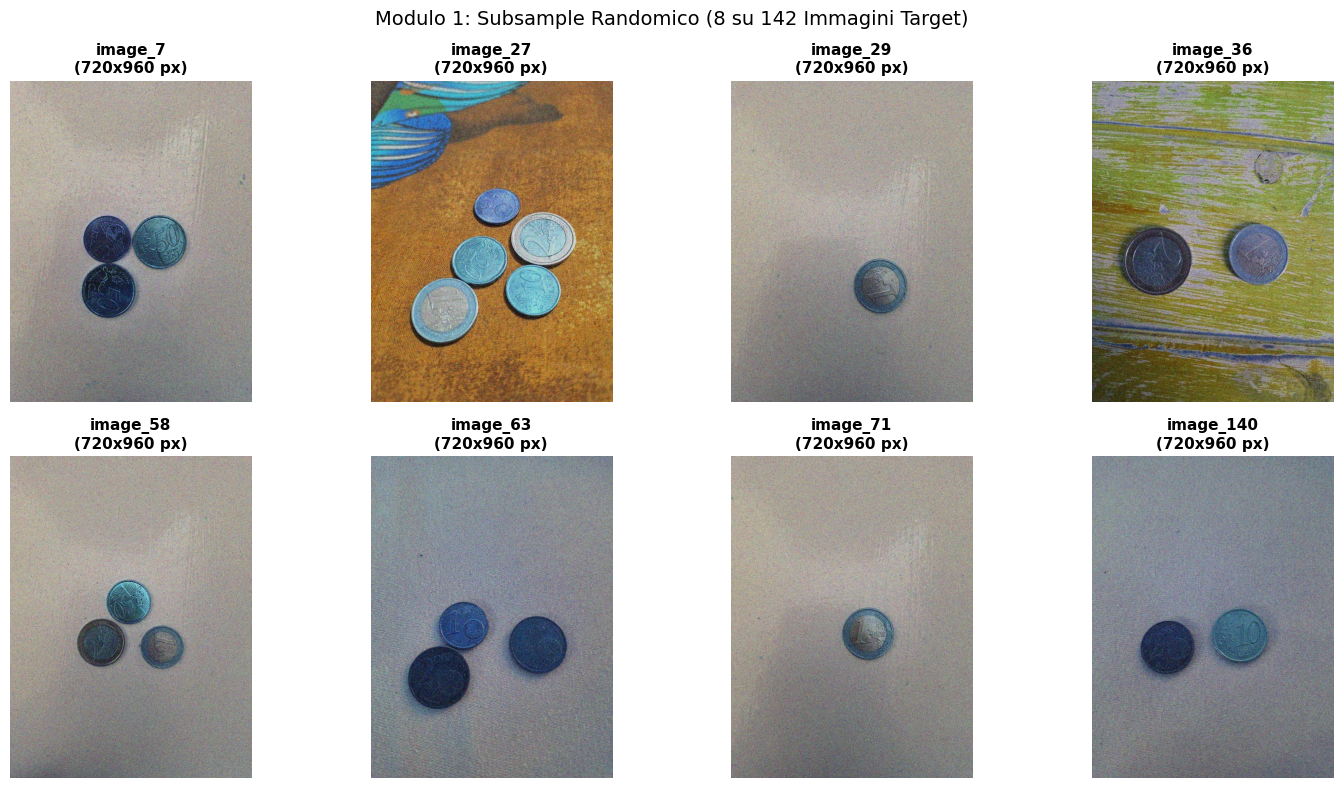

In [2]:
# ==========================================
# MODULO 1: Caricamento Immagini Target
# ==========================================
from module1_load_target import load_target_images, plot_random_sample

# Output in memoria: dizionario con tutte le immagini BGR del target set
target_images = load_target_images()

# Visualizzazione a schermo di un subsample randomico (8 immagini)
plot_random_sample(target_images, n_samples=8, seed=42)


Avvio denoising su 142 immagini target...
  Elaborate 20/142 immagini...
  Elaborate 40/142 immagini...
  Elaborate 60/142 immagini...
  Elaborate 80/142 immagini...
  Elaborate 100/142 immagini...
  Elaborate 120/142 immagini...
  Elaborate 140/142 immagini...
  Elaborate 142/142 immagini...
Denoising completato! Salvate 142 immagini in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module2_denoise_for_detection
Grafico riassuntivo del denoising salvato in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module2_denoise_for_detection\denoise_summary.png


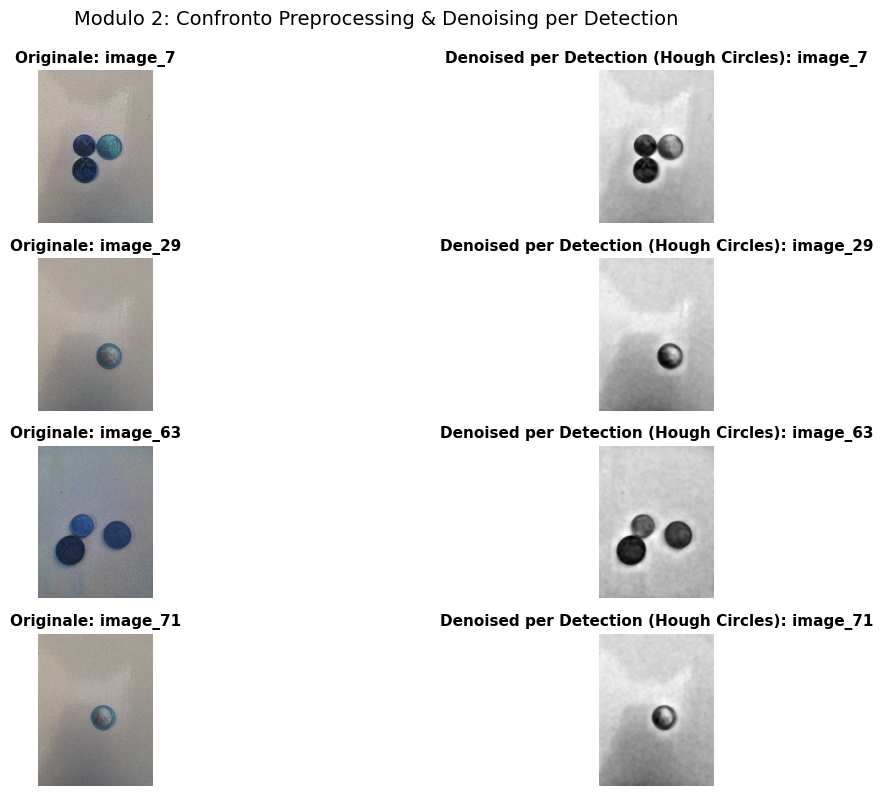

In [3]:
# ==========================================
# MODULO 2: Denoising per Detection (Hough Circles)
# ==========================================
from module2_denoise_for_detection import (
    load_or_create_denoise_params,
    denoise_target_images,
    plot_denoise_comparison
)

# 1. Caricamento parametri da pipeline/conf/Flow_B_Target/denoise_for_detection_params.json
denoise_params = load_or_create_denoise_params()

# 2. Esecuzione del loop di denoising sulle immagini target
# Input: target_images (output del Modulo 1)
# Output: denoised_target_images (dizionario {nome_immagine: immagine_gray_filtrata})
# Serializzazione: pipeline/artifacts/Flow_B_Target/module2_denoise_for_detection/{nome}.png
denoised_target_images = denoise_target_images(target_images, params=denoise_params, save_artifacts=True)

# 3. Visualizzazione a schermo del confronto (Originale vs Denoised per Detection)
plot_denoise_comparison(target_images, denoised_target_images, n_samples=4, seed=42)
